In [ ]:
"""
Helen Dataset Preprocessing Pipeline
======================================
Step 1 — MTCNN filtering on sharp images (original resolution)
Step 2 — Resize to 256x256 with aspect-ratio-preserving padding
Step 3 — Save 4 blur variants per image:
            - low        : original Helen blur (resized)
            - medium     : synthetic 20px horizontal motion blur
            - high       : synthetic 30px horizontal motion blur
            - very_high  : synthetic 45px horizontal motion blur
Step 4 — Run MTCNN on all blur variants to record baseline detection rates

Input structure:
    /content/Helen/
        train/  validation/  test/
            sharp/
            blur/

Output structure:
    /content/processed/
        train/  validation/  test/
            sharp/
                1.jpg ...
            blur/
                1_low.jpg
                1_medium.jpg
                1_high.jpg
                1_very_high.jpg
        filter_log.csv
        detection_baseline.csv   <- MTCNN detection rates per blur level

Requirements:
    pip install facenet-pytorch opencv-python tqdm
"""

'\nHelen Dataset Preprocessing Pipeline\n======================================\nStep 1 — MTCNN filtering on sharp images (original resolution)\nStep 2 — Resize to 256x256 with aspect-ratio-preserving padding\nStep 3 — Save 4 blur variants per image:\n            - low        : original Helen blur (resized)\n            - medium     : synthetic 20px horizontal motion blur\n            - high       : synthetic 30px horizontal motion blur\n            - very_high  : synthetic 45px horizontal motion blur\nStep 4 — Run MTCNN on all blur variants to record baseline detection rates\n\nInput structure:\n    /content/Helen/\n        train/  validation/  test/\n            sharp/\n            blur/\n\nOutput structure:\n    /content/processed/\n        train/  validation/  test/\n            sharp/\n                1.jpg ...\n            blur/\n                1_low.jpg\n                1_medium.jpg\n                1_high.jpg\n                1_very_high.jpg\n        filter_log.csv\n        de

In [ ]:
# pip install facenet-pytorch opencv-python tqdm

In [ ]:
!gdown https://drive.google.com/uc?id=1eD8farAN4uco1m8mF2SvTBs-2q7ouh7y

Downloading...
From (original): https://drive.google.com/uc?id=1eD8farAN4uco1m8mF2SvTBs-2q7ouh7y
From (redirected): https://drive.google.com/uc?id=1eD8farAN4uco1m8mF2SvTBs-2q7ouh7y&confirm=t&uuid=86d40b35-c988-4ab6-ab47-f7c5bc4e96eb
To: /content/Helen.zip
100% 1.09G/1.09G [00:22<00:00, 48.2MB/s]


In [ ]:
!unzip Helen.zip

Archive:  Helen.zip
   creating: Helen/
   creating: Helen/test/
   creating: Helen/test/blur/
  inflating: Helen/test/blur/0.jpg   
  inflating: Helen/test/blur/1.jpg   
  inflating: Helen/test/blur/10.jpg  
  inflating: Helen/test/blur/100.jpg  
  inflating: Helen/test/blur/101.jpg  
  inflating: Helen/test/blur/102.jpg  
  inflating: Helen/test/blur/103.jpg  
  inflating: Helen/test/blur/104.jpg  
  inflating: Helen/test/blur/105.jpg  
  inflating: Helen/test/blur/106.jpg  
  inflating: Helen/test/blur/107.jpg  
  inflating: Helen/test/blur/108.jpg  
  inflating: Helen/test/blur/109.jpg  
  inflating: Helen/test/blur/11.jpg  
  inflating: Helen/test/blur/110.jpg  
  inflating: Helen/test/blur/111.jpg  
  inflating: Helen/test/blur/112.jpg  
  inflating: Helen/test/blur/113.jpg  
  inflating: Helen/test/blur/114.jpg  
  inflating: Helen/test/blur/115.jpg  
  inflating: Helen/test/blur/116.jpg  
  inflating: Helen/test/blur/117.jpg  
  inflating: Helen/test/blur/118.jpg  
  inflating:

In [ ]:
import os
import shutil
import csv
import cv2
import torch
import numpy as np
from tqdm import tqdm
from facenet_pytorch import MTCNN

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [ ]:
DATASET_DIR  = "/content/Helen"
OUTPUT_DIR   = "/content/processed"
LOG_FILE     = os.path.join(OUTPUT_DIR, "filter_log.csv")
BASELINE_FILE = os.path.join(OUTPUT_DIR, "detection_baseline.csv")

SPLITS       = ["train", "validation", "test"]
TARGET_SIZE  = 256

CONFIDENCE_THRESHOLD = 0.90
MIN_FACE_SIZE_RATIO  = 0.05
EDGE_MARGIN          = 2

SUPPORTED_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

BLUR_LEVELS = {
    "medium"    : 20,
    "high"      : 30,
    "very_high" : 45,
}

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [ ]:
mtcnn = MTCNN(
    keep_all=True,
    device=device,
    min_face_size=20,
    thresholds=[0.6, 0.7, 0.90],
    post_process=False
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
def get_image_files(directory):
    files = [f for f in os.listdir(directory)
             if f.lower().endswith(SUPPORTED_EXTENSIONS)]
    return sorted(files)


def resize_with_padding(image, target_size):
    h, w    = image.shape[:2]
    scale   = target_size / max(h, w)
    new_w   = int(w * scale)
    new_h   = int(h * scale)
    resized = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)
    canvas   = np.zeros((target_size, target_size, 3), dtype=np.uint8)
    pad_top  = (target_size - new_h) // 2
    pad_left = (target_size - new_w) // 2
    canvas[pad_top:pad_top + new_h, pad_left:pad_left + new_w] = resized
    return canvas


def make_horizontal_motion_kernel(kernel_size):
    kernel = np.zeros((kernel_size, kernel_size), dtype=np.float32)
    kernel[kernel_size // 2, :] = 1.0 / kernel_size
    return kernel

In [ ]:
def apply_motion_blur(image, kernel_size):
    kernel = make_horizontal_motion_kernel(kernel_size)
    return cv2.filter2D(image, -1, kernel)


def is_valid_face(boxes, probs):
    """Check if any detected face passes confidence threshold."""
    if boxes is None or probs is None:
        return False
    for prob in probs:
        if prob >= CONFIDENCE_THRESHOLD:
            return True
    return False


def mtcnn_detects(image_bgr):
    """Returns True if MTCNN detects a valid face in the image."""
    img_rgb      = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    boxes, probs = mtcnn.detect(img_rgb)
    return is_valid_face(boxes, probs)

In [ ]:
def is_valid_face_full(boxes, probs, image_shape):
    """Full validation check used during filtering step."""
    if boxes is None or probs is None:
        return False, "no_face_detected"

    img_h, img_w = image_shape[:2]
    img_area     = img_h * img_w

    for box, prob in zip(boxes, probs):
        if prob < CONFIDENCE_THRESHOLD:
            continue
        x1, y1, x2, y2 = box
        face_area  = (x2 - x1) * (y2 - y1)
        face_ratio = face_area / img_area
        if face_ratio < MIN_FACE_SIZE_RATIO:
            continue
        if (x1 < EDGE_MARGIN or y1 < EDGE_MARGIN or
                x2 > (img_w - EDGE_MARGIN) or y2 > (img_h - EDGE_MARGIN)):
            continue
        return True, "valid"

    return False, "no_valid_face_after_filters"


In [ ]:
def process_split(split_name, log_rows, baseline_rows):
    sharp_in  = os.path.join(DATASET_DIR, split_name, "sharp")
    blur_in   = os.path.join(DATASET_DIR, split_name, "blur")
    out_sharp = os.path.join(OUTPUT_DIR,  split_name, "sharp")
    out_blur  = os.path.join(OUTPUT_DIR,  split_name, "blur")

    os.makedirs(out_sharp, exist_ok=True)
    os.makedirs(out_blur,  exist_ok=True)

    image_files      = get_image_files(sharp_in)
    total            = len(image_files)
    kept = discarded = missing_original = 0

    # Detection counters per blur level
    detection_counts = {level: 0 for level in ["sharp", "low"] + list(BLUR_LEVELS.keys())}

    print(f"\n[{split_name}] Found {total} sharp images")

    for filename in tqdm(image_files, desc=f"  {split_name}"):
        stem          = os.path.splitext(filename)[0]
        ext           = os.path.splitext(filename)[1]
        sharp_path    = os.path.join(sharp_in, filename)
        original_blur = os.path.join(blur_in,  filename)

        # Load original resolution sharp image
        img_bgr = cv2.imread(sharp_path)
        if img_bgr is None:
            log_rows.append({"split": split_name, "filename": filename,
                             "status": "discarded", "reason": "failed_to_load",
                             "confidence": ""})
            discarded += 1
            continue

        # ── STEP 1: MTCNN filtering on original resolution ──
        img_rgb       = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        boxes, probs  = mtcnn.detect(img_rgb)
        valid, reason = is_valid_face_full(boxes, probs, img_bgr.shape)

        if not valid:
            log_rows.append({"split": split_name, "filename": filename,
                             "status": "discarded", "reason": reason,
                             "confidence": ""})
            discarded += 1
            continue

        # ── STEP 2: Resize sharp to 256x256 ──
        sharp_resized = resize_with_padding(img_bgr, TARGET_SIZE)
        cv2.imwrite(os.path.join(out_sharp, filename), sharp_resized)

        # ── STEP 3a: Resize original Helen blur → save as "low" ──
        has_original = False
        if os.path.exists(original_blur):
            orig_blur_img = cv2.imread(original_blur)
            if orig_blur_img is not None:
                orig_resized = resize_with_padding(orig_blur_img, TARGET_SIZE)
                cv2.imwrite(os.path.join(out_blur, f"{stem}_low{ext}"), orig_resized)
                has_original = True
            else:
                missing_original += 1
        else:
            missing_original += 1

        # ── STEP 3b: Generate 3 synthetic blur levels ──
        blur_images = {}
        for level_name, kernel_size in BLUR_LEVELS.items():
            blurred = apply_motion_blur(sharp_resized, kernel_size)
            cv2.imwrite(os.path.join(out_blur, f"{stem}_{level_name}{ext}"), blurred)
            blur_images[level_name] = blurred

        # ── STEP 4: Run MTCNN on all variants → record detection ──
        # Sharp (resized)
        if mtcnn_detects(sharp_resized):
            detection_counts["sharp"] += 1

        # Low (original blur resized)
        if has_original and mtcnn_detects(orig_resized):
            detection_counts["low"] += 1

        # Synthetic blur levels
        for level_name, blurred_img in blur_images.items():
            if mtcnn_detects(blurred_img):
                detection_counts[level_name] += 1

        # Log baseline row for this image
        baseline_rows.append({
            "split"    : split_name,
            "filename" : filename,
            "sharp"    : mtcnn_detects(sharp_resized),
            "low"      : mtcnn_detects(orig_resized) if has_original else "N/A",
            "medium"   : mtcnn_detects(blur_images["medium"]),
            "high"     : mtcnn_detects(blur_images["high"]),
            "very_high": mtcnn_detects(blur_images["very_high"]),
        })

        log_rows.append({"split": split_name, "filename": filename,
                         "status": "kept", "reason": "valid",
                         "confidence": round(float(np.max(probs)), 4)})
        kept += 1

    # Print detection rates for this split
    print(f"\n  [{split_name}] Baseline MTCNN Detection Rates (out of {kept} kept images):")
    for level, count in detection_counts.items():
        pct = 100 * count / kept if kept > 0 else 0
        print(f"    {level:<12} : {count}/{kept} ({pct:.1f}%)")

    total_pairs = (kept * len(BLUR_LEVELS)) + (kept - missing_original)
    print(f"\n  └─ Kept: {kept}/{total} ({100*kept/total:.1f}%) | "
          f"Discarded: {discarded} | "
          f"Missing original blur: {missing_original} | "
          f"Total blur pairs: {total_pairs}")

    return kept, discarded, total, missing_original, detection_counts

In [ ]:
def run_preprocessing():
    log_rows      = []
    baseline_rows = []
    grand_total   = grand_kept = grand_discarded = grand_missing = 0

    # Aggregate detection counts across all splits
    grand_detection = {level: 0 for level in ["sharp", "low"] + list(BLUR_LEVELS.keys())}

    for split in SPLITS:
        kept, discarded, total, missing, detection_counts = process_split(
            split, log_rows, baseline_rows)
        grand_total     += total
        grand_kept      += kept
        grand_discarded += discarded
        grand_missing   += missing
        for level in grand_detection:
            grand_detection[level] += detection_counts[level]

    # Write filter log CSV
    with open(LOG_FILE, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=["split", "filename", "status", "reason", "confidence"])
        writer.writeheader()
        writer.writerows(log_rows)

    # Write detection baseline CSV
    with open(BASELINE_FILE, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=["split", "filename", "sharp", "low", "medium", "high", "very_high"])
        writer.writeheader()
        writer.writerows(baseline_rows)

    total_pairs = (grand_kept * len(BLUR_LEVELS)) + (grand_kept - grand_missing)

    print("\n" + "="*55)
    print("PREPROCESSING COMPLETE — OVERALL SUMMARY")
    print("="*55)
    print(f"Total images processed : {grand_total}")
    print(f"Kept after filtering   : {grand_kept}  ({100*grand_kept/grand_total:.1f}%)")
    print(f"Discarded              : {grand_discarded}  ({100*grand_discarded/grand_total:.1f}%)")
    print(f"Missing original blur  : {grand_missing}")
    print(f"Total blur pairs       : {total_pairs}")
    print(f"Image size             : {TARGET_SIZE}×{TARGET_SIZE}px")
    print(f"Filter log             : {LOG_FILE}")
    print(f"Detection baseline     : {BASELINE_FILE}")
    print(f"Processed dataset      : {OUTPUT_DIR}")
    print("="*55)
    print(f"\nOverall Baseline MTCNN Detection Rates (all splits, {grand_kept} images):")
    for level, count in grand_detection.items():
        pct = 100 * count / grand_kept if grand_kept > 0 else 0
        bar = "█" * int(pct // 5) + "░" * (20 - int(pct // 5))
        print(f"  {level:<12} : {bar} {count}/{grand_kept} ({pct:.1f}%)")
    print("\nMethodology sentence to use in your paper:")
    print(f'  "From {grand_total} Helen dataset images, {grand_kept} ({100*grand_kept/grand_total:.1f}%)')
    print(f'   were retained after MTCNN filtering with confidence threshold {CONFIDENCE_THRESHOLD}.')
    print(f'   Each image was resized to {TARGET_SIZE}×{TARGET_SIZE}px with aspect-ratio-preserving')
    print(f'   padding, then paired with four blur variants: the original Helen')
    print(f'   blur (low) and three synthetic horizontal motion blur levels')
    print(f'   (medium: 20px, high: 30px, very high: 45px),')
    print(f'   yielding {total_pairs} total image pairs."')

In [ ]:
run_preprocessing()


[train] Found 2000 sharp images


  train: 100%|██████████| 2000/2000 [32:14<00:00,  1.03it/s]



  [train] Baseline MTCNN Detection Rates (out of 1762 kept images):
    sharp        : 1760/1762 (99.9%)
    low          : 1760/1762 (99.9%)
    medium       : 1694/1762 (96.1%)
    high         : 1075/1762 (61.0%)
    very_high    : 272/1762 (15.4%)

  └─ Kept: 1762/2000 (88.1%) | Discarded: 238 | Missing original blur: 0 | Total blur pairs: 7048

[validation] Found 165 sharp images


  validation: 100%|██████████| 165/165 [02:48<00:00,  1.02s/it]



  [validation] Baseline MTCNN Detection Rates (out of 153 kept images):
    sharp        : 153/153 (100.0%)
    low          : 153/153 (100.0%)
    medium       : 150/153 (98.0%)
    high         : 115/153 (75.2%)
    very_high    : 26/153 (17.0%)

  └─ Kept: 153/165 (92.7%) | Discarded: 12 | Missing original blur: 0 | Total blur pairs: 612

[test] Found 165 sharp images


  test: 100%|██████████| 165/165 [02:53<00:00,  1.05s/it]


  [test] Baseline MTCNN Detection Rates (out of 156 kept images):
    sharp        : 155/156 (99.4%)
    low          : 156/156 (100.0%)
    medium       : 150/156 (96.2%)
    high         : 101/156 (64.7%)
    very_high    : 30/156 (19.2%)

  └─ Kept: 156/165 (94.5%) | Discarded: 9 | Missing original blur: 0 | Total blur pairs: 624

PREPROCESSING COMPLETE — OVERALL SUMMARY
Total images processed : 2330
Kept after filtering   : 2071  (88.9%)
Discarded              : 259  (11.1%)
Missing original blur  : 0
Total blur pairs       : 8284
Image size             : 256×256px
Filter log             : /content/processed/filter_log.csv
Detection baseline     : /content/processed/detection_baseline.csv
Processed dataset      : /content/processed

Overall Baseline MTCNN Detection Rates (all splits, 2071 images):
  sharp        : ███████████████████░ 2068/2071 (99.9%)
  low          : ███████████████████░ 2069/2071 (99.9%)
  medium       : ███████████████████░ 1994/2071 (96.3%)
  high         : █

Displaying 3 random samples from [train] split



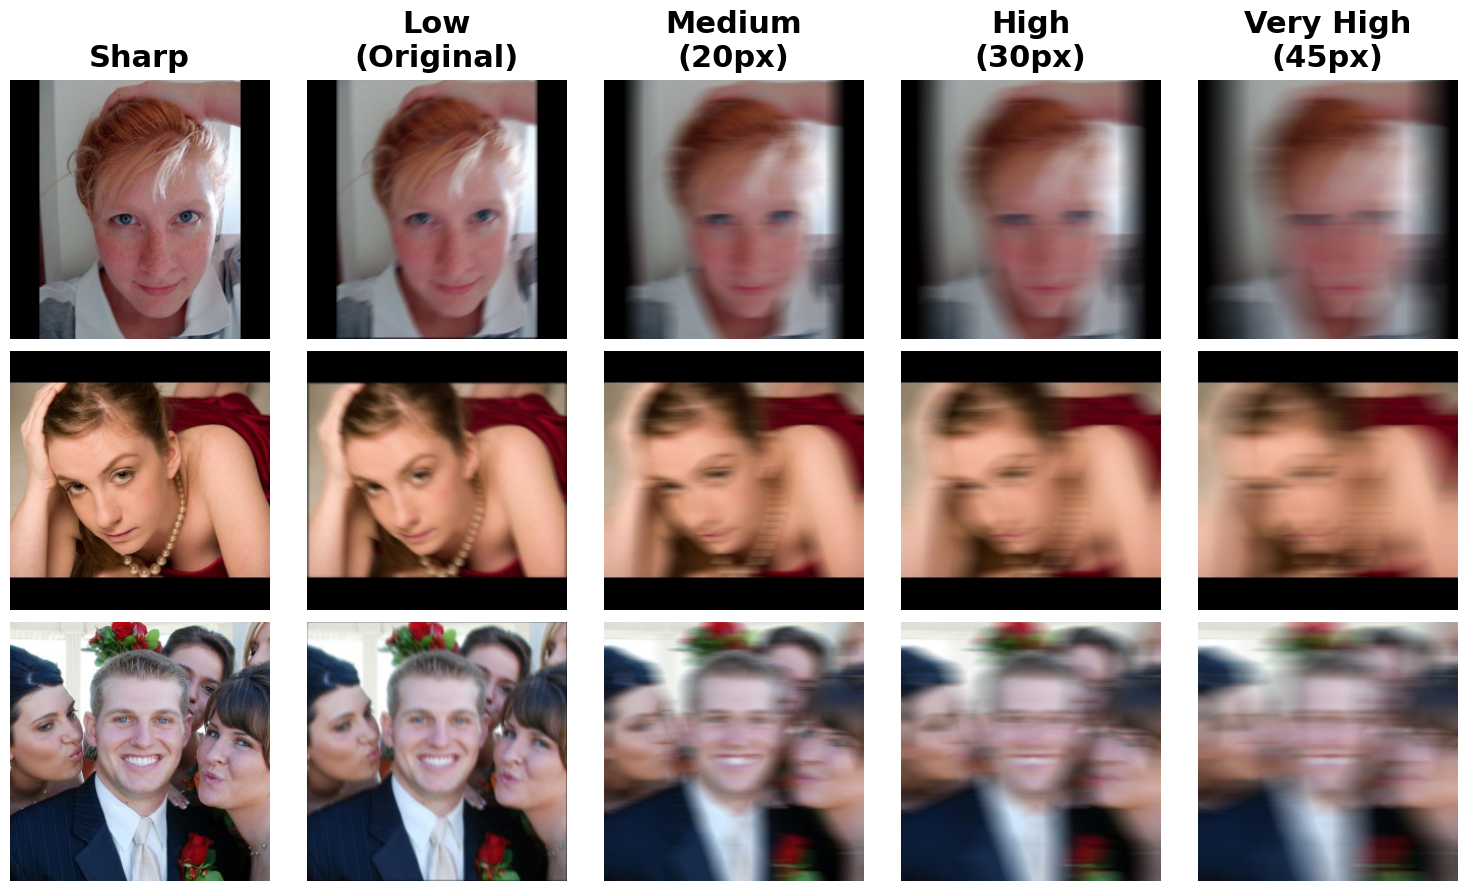


Preview saved to /content/dataset_preview_train.png


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# ─────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────

PROCESSED_DIR = "/content/processed"
SPLIT         = "train"          # change to "validation" or "test" if needed
NUM_SAMPLES   = 3
RANDOM_SEED   = 42

# ─────────────────────────────────────────────
# LOAD AND DISPLAY
# ─────────────────────────────────────────────

sharp_dir = os.path.join(PROCESSED_DIR, SPLIT, "sharp")
blur_dir  = os.path.join(PROCESSED_DIR, SPLIT, "blur")

# Get all sharp filenames
sharp_files = sorted([
    f for f in os.listdir(sharp_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Pick random samples
random.seed(RANDOM_SEED)
samples = random.sample(sharp_files, min(NUM_SAMPLES, len(sharp_files)))

# Single source of truth: (key, label) pairs, in display order.
# This replaces the old paths.keys()/labels zip — that relied on dict
# insertion order matching a separately-maintained labels list, which
# would silently mislabel columns if the two ever drifted out of sync.
variants = [
    ("sharp",     "Sharp"),
    ("low",       "Low\n(Original)"),
    ("medium",    "Medium\n(20px)"),
    ("high",      "High\n(30px)"),
    ("very_high", "Very High\n(45px)"),
]
cols = len(variants)

fig, axes = plt.subplots(
    len(samples), cols,
    figsize=(cols * 3, len(samples) * 3)
)

# Handle single row case
if len(samples) == 1:
    axes = [axes]

print(f"Displaying {len(samples)} random samples from [{SPLIT}] split\n")

for row, filename in enumerate(samples):
    stem = os.path.splitext(filename)[0]
    ext  = os.path.splitext(filename)[1]

    # Build paths for each variant
    paths = {
        "sharp"    : os.path.join(sharp_dir, filename),
        "low"      : os.path.join(blur_dir,  f"{stem}_low{ext}"),
        "medium"   : os.path.join(blur_dir,  f"{stem}_medium{ext}"),
        "high"     : os.path.join(blur_dir,  f"{stem}_high{ext}"),
        "very_high": os.path.join(blur_dir,  f"{stem}_very_high{ext}"),
    }

    for col, (key, label) in enumerate(variants):
        ax  = axes[row][col]
        img = cv2.imread(paths[key])

        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            # Show blank with missing label if file not found
            ax.imshow(np.zeros((256, 256, 3), dtype=np.uint8))
            ax.text(128, 128, "missing", color="red",
                    ha="center", va="center", fontsize=12, fontweight="bold",
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=2))

        ax.axis("off")

        # Column headers on first row only
        if row == 0:
            ax.set_title(label, fontsize=22, fontweight="bold", pad=10)

        # Filename on leftmost column
        if col == 0:
            ax.set_ylabel(filename, fontsize=10, fontweight="bold", rotation=0,
                         labelpad=70, va="center")

# plt.suptitle(f"Processed Dataset Preview — {SPLIT} split",
            #  fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

out_path = f"/content/dataset_preview_{SPLIT}.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"\nPreview saved to {out_path}")